# 03 — Q2b: Which programs stand out — pathway enrichment and sample-level program tests

Two independent methods, and a program "stands out" only where they agree:

| method | input | unit | what it tests |
|---|---|---|---|
| **GSEA prerank** | each `02` DESeq2 Wald statistic | gene ranking | does the set concentrate at one end of the ranking? Every GMT set with 10-500 genes, BH over the whole collection |
| **program-score contrast** | sample-level score (mean gene z of log CPM) | sample / mouse | does the score move, with an **exact relabelling** null over the samples the design allows? |

GSEA cannot see a 1-3 gene chemokine axis (minimum set size 10), so **chemokine axes use only
the sample-level test plus `02`'s gene-level results** — never GSEA.

Effects, as everywhere in this folder:
* **PSCA** — PSCA − TAG72 within the non-RT and RT strata (site-matched); main = mean of the two
  strata, `interaction` = RT stratum − non-RT stratum = CAR × RT;
* **direct RT** — Tu1, PSCA and TAG72 backgrounds; **indirect RT** — Tu2;
* **DiD** — (Tu1 − Tu2)_RT − (Tu1 − Tu2)_non-RT, mice paired, per background.

Program-score effects are in **within-arm SD units**. Each also gets a **random-program
percentile** (expression-matched random gene sets of the same size): necessary, not sufficient —
co-regulated programs beat random genes whenever they move at all.

**Sensitivity variants** sit beside their parents: `cyto_effector` vs `cyto_effector_noCcl5`, and
`exh_progenitor` vs `exh_progenitor_noXcl1`.

## 1. Config

In [1]:
import warnings; warnings.filterwarnings("ignore")
import json, itertools, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from statsmodels.stats.multitest import multipletests

pd.set_option("display.width", 280); pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 500)
_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
OUT = PROJ/"results/mhc_cytotox"; FIG = OUT/"figures"
GMT_DIR = PROJ/"data/references/pathways"
MIN_CELLS, N_PERM, N_RANDOM, SEED = 10, 1000, 300, 0
MIN_SIZE, MAX_SIZE = 10, 500
RECOMPUTE_GSEA = False            # gsea_all.parquet is reused unless this is True
rng = np.random.default_rng(SEED)

PB = pd.read_parquet(OUT/"pseudobulk_counts.parquet")
PBM = pd.read_csv(OUT/"pseudobulk_meta.csv").set_index("key").loc[PB.index]
CAT = json.load(open(OUT/"programs.json")); PROGRAMS, AXES = CAT["programs"], CAT["axes"]
DE = pd.read_parquet(OUT/"de_all.parquet")
REPL = pd.read_csv(OUT/"de_panel_replication.csv")
L = np.log2(PB.div(PB.sum(1), axis=0) * 1e6 + 1)

GROUPS = ["Cancer_cell", "IFN_stimulated_Mac", "M2_like_Mac", "Intermediate_Mac", "Classical_Mono",
          "cDC", "N1_like_Neu", "NK", "CD8_T", "cytotoxic_lymph", "SPP1_TAM"]
FAM_ORDER = ["MHC-I", "MHC-II", "IFN", "cytotoxicity", "exhaustion", "checkpoint", "chemokine",
             "chemokine-pathway", "control"]

## 2. GSEA prerank over the whole GMT collection

The weighted-KS engine of `spp1Analysis/10` (`_es_at_hits`). One change for speed: the
permutation null of a set depends only on its **size** and the ranking, so it is computed once
per distinct size and shared by every set of that size.

In [2]:
def read_gmt(p_):
    out = {}
    for line in open(p_):
        x = line.rstrip("\n").split("\t")
        if len(x) >= 3: out[x[0]] = x[2:]
    return out


GMT = {}
for f_ in sorted(GMT_DIR.glob("*.gmt")): GMT.update(read_gmt(f_))
for k, v in PROGRAMS.items():                       # curated modules large enough for GSEA
    if v["source"] == "curated" and len(v["genes"]) >= MIN_SIZE: GMT[f"CURATED_{k}"] = v["genes"]
FAMILY_OF = {}
for k, v in PROGRAMS.items():
    FAMILY_OF[v["source"].replace("GMT:", "") if v["source"] != "curated" else f"CURATED_{k}"] = v["family"]
print(f"{len(GMT):,} gene sets in the collection; {len(FAMILY_OF)} tagged to a program family")


def _es_at_hits(pos, wcum, Wtot, N, n):
    i = np.arange(1, n + 1)
    after = wcum / Wtot
    before = np.concatenate([np.zeros(pos.shape[:-1] + (1,)), wcum[..., :-1]], axis=-1) / Wtot
    dev = np.concatenate([after - (pos + 1 - i) / (N - n), before - (pos - i + 1) / (N - n)], axis=-1)
    hi, lo = np.maximum(dev.max(axis=-1), 0.0), np.minimum(dev.min(axis=-1), 0.0)
    return np.where(hi >= -lo, hi, lo)


def gsea_prerank(ranking, sets, n_perm=N_PERM, seed=SEED):
    r = ranking.dropna().sort_values(ascending=False)
    w, N = np.abs(r.to_numpy(float)), len(r)
    idx = pd.Series(np.arange(N), index=r.index)
    POS = {}
    for name, members in sets.items():
        m = idx.reindex(pd.Index(list(set(members)))).dropna().to_numpy(int)
        if MIN_SIZE <= len(m) <= MAX_SIZE: POS[name] = np.sort(m)
    if not POS: return pd.DataFrame()
    g_ = np.random.default_rng(seed)
    maxn = max(len(v) for v in POS.values())
    PERM = np.argsort(g_.random((n_perm, N)), axis=1)[:, :maxn]          # shared random orders
    NULL = {}
    for n in sorted({len(v) for v in POS.values()}):
        pos = np.sort(PERM[:, :n], axis=1)
        NULL[n] = _es_at_hits(pos, np.cumsum(w[pos], axis=1), w[pos].sum(1)[:, None], N, n)
    rows = []
    for name, pos in POS.items():
        n = len(pos)
        es = float(_es_at_hits(pos, np.cumsum(w[pos]), w[pos].sum(), N, n))
        null = NULL[n]; pn, nn_ = null[null >= 0], null[null < 0]
        if es >= 0: nes = es / pn.mean(); p = (1 + (pn >= es).sum()) / (1 + len(pn))
        else:       nes = -es / nn_.mean(); p = (1 + (nn_ <= es).sum()) / (1 + len(nn_))
        rows.append(dict(pathway=name, size=n, ES=es, NES=float(nes), pval=float(p)))
    out = pd.DataFrame(rows)
    out["FDR"] = multipletests(out.pval, method="fdr_bh")[1]
    return out


GS_FILE = OUT/"gsea_all.parquet"
if GS_FILE.exists() and not RECOMPUTE_GSEA:
    GS = pd.read_parquet(GS_FILE); print(f"loaded {GS_FILE.name}: {len(GS):,} rows")
else:
    res, t0 = [], time.time()
    for (g_, c_), d in DE[DE.group.isin(GROUPS)].groupby(["group", "contrast"]):
        rk = d.set_index("gene")["stat"]
        out = gsea_prerank(rk, GMT, seed=SEED)
        res.append(out.assign(group=g_, contrast=c_))
    GS = pd.concat(res, ignore_index=True)
    GS["family"] = GS.pathway.map(FAMILY_OF)
    GS.to_parquet(GS_FILE)
    print(f"GSEA: {GS.groupby(['group', 'contrast']).ngroups} rankings, {len(GS):,} set tests, "
          f"{time.time()-t0:.0f}s")

# positive control: PSCA vs TAG72 IFN-gamma in macrophages (spp1Analysis/10: NES ~ +3.2)
pc = GS[(GS.pathway == "HALLMARK_INTERFERON_GAMMA_RESPONSE") & GS.contrast.isin(["PSCA_nonRT", "PSCA_RT", "TxNoTx"])]
print("\npositive control — Hallmark IFN-gamma NES:")
print(pc.pivot_table(index="group", columns="contrast", values="NES").round(2).to_string())

9,622 gene sets in the collection; 65 tagged to a program family
loaded gsea_all.parquet: 478,163 rows

positive control — Hallmark IFN-gamma NES:
contrast            PSCA_RT  PSCA_nonRT  TxNoTx
group                                          
CD8_T                  1.82        1.15     NaN
Cancer_cell            2.36       -1.26    3.04
Classical_Mono         3.13        3.31    3.25
IFN_stimulated_Mac     2.91        3.03    3.23
Intermediate_Mac       3.14        3.49    3.39
M2_like_Mac            3.23        3.34    3.41
N1_like_Neu            2.80        2.24    2.65
NK                     1.87        1.49     NaN
SPP1_TAM               3.21        3.16    3.34
cDC                    2.97        2.56    2.62
cytotoxic_lymph        1.95        2.08    1.43


## 3. GSEA, focused on the program families

Every set tagged to a family (MHC, IFN, cytotoxicity, exhaustion, checkpoint, chemokine
pathways, controls), reported for the three effects with the replication rule: **same sign in
both strata (PSCA) or both backgrounds (RT), FDR < 0.05 in at least one and nominal p < 0.05 in
both.**

In [3]:
EFFECTS = {"PSCA": ("PSCA_nonRT", "PSCA_RT"), "direct RT": ("directRT_PSCA", "directRT_TAG72"),
           "indirect RT": ("indirectRT_PSCA", "indirectRT_TAG72"), "DiD": ("DiD_PSCA", "DiD_TAG72")}
fam = GS[GS.family.notna()]
grows = []
for name, (c1, c2) in EFFECTS.items():
    a = fam[fam.contrast == c1].set_index(["group", "pathway"])
    b = fam[fam.contrast == c2].set_index(["group", "pathway"])
    j = a[["family", "size", "NES", "pval", "FDR"]].join(b[["NES", "pval", "FDR"]], rsuffix="_2",
                                                         how="inner")
    j["effect"] = name
    j["replicated"] = ((np.sign(j.NES) == np.sign(j.NES_2)) & (j.pval < 0.05) & (j.pval_2 < 0.05)
                       & (j[["FDR", "FDR_2"]].min(1) < 0.05))
    grows.append(j.reset_index())
GF = pd.concat(grows, ignore_index=True)
GF.to_csv(OUT/"gsea_family_replication.csv", index=False)
for name in EFFECTS:
    d = GF[(GF.effect == name) & GF.replicated].copy()
    d["family"] = pd.Categorical(d.family, FAM_ORDER, ordered=True)
    print(f"\n=== GSEA {name.upper()} — family sets replicated ({len(d)}) ===")
    print(d.sort_values(["family", "group"])[["family", "group", "pathway", "size", "NES", "FDR", "NES_2", "FDR_2"]]
            .round(3).to_string(index=False) if len(d) else "    none")
for c_ in ["CARxRT"]:
    d = GS[(GS.contrast == c_) & GS.family.notna() & (GS.FDR < 0.05)]
    print(f"\n=== GSEA {c_} — family sets at FDR < 0.05 ({len(d)}) ===")
    print(d.sort_values(["family", "group"])[["family", "group", "pathway", "size", "NES", "FDR"]]
            .round(3).to_string(index=False) if len(d) else "    none")


=== GSEA PSCA — family sets replicated (100) ===
           family              group                                                                                        pathway  size    NES   FDR  NES_2  FDR_2
            MHC-I     Classical_Mono              REACTOME_ANTIGEN_PRESENTATION_FOLDING_ASSEMBLY_AND_PEPTIDE_LOADING_OF_CLASS_I_MHC    22  1.844 0.025  1.832  0.101
            MHC-I     Classical_Mono                                  REACTOME_CLASS_I_MHC_MEDIATED_ANTIGEN_PROCESSING_PRESENTATION   276  1.710 0.025  1.898  0.059
            MHC-I     Classical_Mono                                                                        CURATED_MHC_I_machinery    14  2.161 0.025  2.212  0.063
            MHC-I IFN_stimulated_Mac              REACTOME_ANTIGEN_PRESENTATION_FOLDING_ASSEMBLY_AND_PEPTIDE_LOADING_OF_CLASS_I_MHC    22  2.034 0.029  1.906  0.071
            MHC-I IFN_stimulated_Mac                                  REACTOME_CLASS_I_MHC_MEDIATED_ANTIGEN_PROCESSING_PRESEN

## 4. Sample-level program scores and the exact-relabelling engine

In [4]:
def group_scores(group):
    d = PBM[(PBM.group == group) & (PBM.n_cells >= MIN_CELLS)]
    Lg = L.loc[d.index]
    expressed = Lg.columns[(Lg.mean() >= 1.0).values]                 # >= ~1 CPM on average
    tr = d.arm != "NoTx"
    mu, sd = Lg.loc[tr.values, expressed].mean(), Lg.loc[tr.values, expressed].std().replace(0, np.nan)
    Z = ((Lg[expressed] - mu) / sd).dropna(axis=1)
    sc, kept = {}, {}
    for k, v in PROGRAMS.items():
        gl = [g for g in v["genes"] if g in Z.columns]
        need = 1 if v["family"] == "chemokine" else 3
        if len(gl) >= need:
            sc[k] = Z[gl].mean(1); kept[k] = gl
    S = pd.DataFrame(sc); S.index = d["sample"].values
    meta = d.set_index("sample")[["arm", "site", "mouse"]]
    return S, meta, Z.set_axis(d["sample"].values), kept


def cell_null(S, meta, A, B, site):
    idx = meta.index[meta.arm.isin([A, B]) & (meta.site == site)]
    obs = (meta.loc[idx, "arm"] == A).values; k, n = int(obs.sum()), len(idx)
    if k < 2 or n - k < 2: return None
    X = S.loc[idx].values
    ms = [obs] + [m for m in (np.isin(np.arange(n), c) for c in itertools.combinations(range(n), k))
                  if not (m == obs).all()]
    return np.vstack([X[m].mean(0) - X[~m].mean(0) for m in ms])


def did_null(S, meta, rt_arm, ct_arm):
    def diffs(arm):
        d = S.join(meta)[meta.arm == arm]
        w = d.reset_index().pivot_table(index="mouse", columns="site", values=list(S.columns))
        return pd.DataFrame({c: w[c][1] - w[c][2] for c in S.columns
                             if 1 in w[c].columns and 2 in w[c].columns}).dropna()
    A, B = diffs(rt_arm), diffs(ct_arm)
    if len(A) < 2 or len(B) < 2: return None
    X = pd.concat([A, B])[list(S.columns)].values
    obs = np.r_[np.ones(len(A), bool), np.zeros(len(B), bool)]
    ms = [obs] + [m for m in (np.isin(np.arange(len(X)), c) for c in itertools.combinations(range(len(X)), len(A)))
                  if not (m == obs).all()]
    return np.vstack([X[m].mean(0) - X[~m].mean(0) for m in ms])


def combine(nulls, how="mean", cap=60000, seed=SEED):
    g_ = np.random.default_rng(seed)
    nulls = [n_ if len(n_) * 1 <= cap else np.vstack([n_[:1], n_[1:][g_.choice(len(n_) - 1, cap, replace=False)]])
             for n_ in nulls]
    out = nulls[0]
    for k, nb in enumerate(nulls[1:], start=2):
        if how == "mean":
            out = ((out[:, None, :] * (k - 1) + nb[None, :, :]) / k).reshape(-1, out.shape[1])
        else:
            out = (out[:, None, :] - nb[None, :, :]).reshape(-1, out.shape[1])
        if len(out) > cap:
            out = np.vstack([out[:1], out[1:][g_.choice(len(out) - 1, cap, replace=False)]])
    return out


def pval(null): return (np.abs(null) >= np.abs(null[0])[None, :] - 1e-12).mean(0)


def effect_strata(S, meta):
    """{effect: {stratum: null matrix}} — row 0 of each null is the observed delta."""
    E = {}
    E["PSCA"] = {}
    for st, (A, B) in {"nonRT": ("CyPSCA", "CyT72"), "RT": ("RTCyPSCA", "RTCyT72")}.items():
        cells = [n_ for s in (1, 2) if (n_ := cell_null(S, meta, A, B, s)) is not None]
        if cells: E["PSCA"][st] = combine(cells)
    for name, site in [("direct RT", 1), ("indirect RT", 2)]:
        E[name] = {}
        for bg, (A, B) in {"PSCA": ("RTCyPSCA", "CyPSCA"), "TAG72": ("RTCyT72", "CyT72")}.items():
            n_ = cell_null(S, meta, A, B, site)
            if n_ is not None: E[name][bg] = n_
    E["DiD"] = {}
    for bg, (A, B) in {"PSCA": ("RTCyPSCA", "CyPSCA"), "TAG72": ("RTCyT72", "CyT72")}.items():
        n_ = did_null(S, meta, A, B)
        if n_ is not None: E["DiD"][bg] = n_
    return E


def effect_table(S, meta, sdw):
    rows = []
    for eff, strata in effect_strata(S, meta).items():
        if not strata: continue
        names = list(strata)
        for j, prog in enumerate(S.columns):
            r = dict(effect=eff, program=prog)
            for s_ in names:
                r[f"d_{s_}"] = strata[s_][0, j] / sdw[prog]; r[f"p_{s_}"] = float(pval(strata[s_][:, [j]])[0])
            if len(names) == 2:
                main = combine([strata[names[0]][:, [j]], strata[names[1]][:, [j]]], "mean")
                # interaction is always CAR x RT = (RT effect in PSCA) - (RT effect in TAG72):
                # RT stratum - nonRT stratum for the PSCA effect; PSCA - TAG72 background for RT effects
                hi, lo = (names[1], names[0]) if eff == "PSCA" else (names[0], names[1])
                inter = combine([strata[hi][:, [j]], strata[lo][:, [j]]], "diff")
                r.update(strata=f"{names[0]}|{names[1]}", d_1=r[f"d_{names[0]}"], d_2=r[f"d_{names[1]}"],
                         main=main[0, 0] / sdw[prog], p_main=float(pval(main)[0]),
                         interaction=inter[0, 0] / sdw[prog], p_inter=float(pval(inter)[0]),
                         sign_agree=bool(np.sign(r[f"d_{names[0]}"]) == np.sign(r[f"d_{names[1]}"])))
            rows.append(r)
    return pd.DataFrame(rows)


def sd_within(S, meta):
    t = S.join(meta)[meta.arm != "NoTx"]
    return t.groupby(["arm", "site"])[list(S.columns)].var().mean().pow(0.5).replace(0, np.nan)

## 5. Program-score contrasts in every cell group, with the random-program control

In [5]:
def observed_main(S, meta):
    """Observed main effect per effect, for many columns at once (no nulls) — used for random sets."""
    out = {}
    for eff, strata in effect_strata(S, meta).items():
        if len(strata) == 2:
            a, b = list(strata.values())
            out[eff] = (a[0] + b[0]) / 2
    return out


PT, t0 = [], time.time()
for g_ in GROUPS:
    S, meta, Z, kept = group_scores(g_)
    sdw = sd_within(S, meta)
    T = effect_table(S, meta, sdw)
    # random expression-matched programs, per program size
    dec = pd.qcut(L.loc[PBM[(PBM.group == g_) & (PBM.n_cells >= MIN_CELLS)].index, Z.columns].mean()
                  .rank(method="first"), 10, labels=False)
    pool = {d_: np.array(dec.index[dec == d_]) for d_ in range(10)}
    pct = []
    for prog, gl in kept.items():
        mix = dec.loc[gl].value_counts()
        R = pd.DataFrame({f"r{i}": Z[np.concatenate([rng.choice(pool[d_], min(n_, len(pool[d_])), replace=False)
                                                     for d_, n_ in mix.items()])].mean(1)
                          for i in range(N_RANDOM)})
        sdr = sd_within(R, meta)
        om = observed_main(R, meta)
        for eff, v in om.items():
            obs = T[(T.effect == eff) & (T.program == prog)]["main"]
            if len(obs) and np.isfinite(obs.iloc[0]):
                pct.append(dict(effect=eff, program=prog,
                                rand_pct=float((np.abs(v / sdr.values) < abs(obs.iloc[0])).mean())))
    T = T.merge(pd.DataFrame(pct), on=["effect", "program"], how="left")
    T["group"] = g_; T["n_genes"] = T.program.map({k: len(v) for k, v in kept.items()})
    PT.append(T)
    print(f"  {g_:<20s} {S.shape[0]:>2d} samples, {S.shape[1]} programs  {time.time()-t0:5.0f}s", flush=True)
PT = pd.concat(PT, ignore_index=True)
PT["family"] = PT.program.map({k: v["family"] for k, v in PROGRAMS.items()})
PT["role"] = PT.program.map({k: v["role"] for k, v in PROGRAMS.items()})
PT.to_csv(OUT/"program_score_contrasts.csv", index=False)
print("p-value floors: per stratum ~1/C(n,k) (10-20 relabellings at 2-3 v 2-3); joint main effect "
      "down to ~1/400.")

  Cancer_cell          29 samples, 58 programs     31s


  IFN_stimulated_Mac   29 samples, 57 programs     61s


  M2_like_Mac          29 samples, 56 programs     91s


  Intermediate_Mac     29 samples, 57 programs    119s


  Classical_Mono       29 samples, 58 programs    148s


  cDC                  29 samples, 58 programs    177s


... (2 outputs left out)

  CD8_T                16 samples, 61 programs    263s


  cytotoxic_lymph      27 samples, 61 programs    293s


  SPP1_TAM             29 samples, 55 programs    321s


p-value floors: per stratum ~1/C(n,k) (10-20 relabellings at 2-3 v 2-3); joint main effect down to ~1/400.


## 6. What stands out — the two methods together

* **Programs with >= 10 genes:** GSEA replicated (`§3` rule) **and** the program score agrees in
  sign with `p_main < 0.10`.
* **Chemokine axes (1-5 genes):** at least one axis gene replicated in `02` (DE rule) **and** the
  axis score agrees in sign with `p_main < 0.10`.
* Everything is also reported for the **interaction**, which `rtAdvantage` found is where RT
  actually acts.

In [6]:
GSET_OF = {k: (v["source"].replace("GMT:", "") if v["source"] != "curated" else f"CURATED_{k}")
           for k, v in PROGRAMS.items()}
SO = []
for _, r in PT[PT.effect.isin(["PSCA", "direct RT", "indirect RT", "DiD"])].iterrows():
    s = dict(group=r.group, program=r.program, family=r.family, role=r.role, effect=r.effect,
             n_genes=r.n_genes, score_main=r.get("main"), score_p=r.get("p_main"),
             score_agree=r.get("sign_agree"), score_inter=r.get("interaction"),
             score_p_inter=r.get("p_inter"), rand_pct=r.get("rand_pct"))
    if r.family == "chemokine":
        gl = PROGRAMS[r.program]["genes"]
        rep = REPL[(REPL.group == r.group) & (REPL.effect == r.effect) & REPL.gene.isin(gl) & REPL.replicated]
        s["gene_level"] = ", ".join(f"{x.gene}({x.lfc_1:+.1f}/{x.lfc_2:+.1f})" for _, x in rep.iterrows())
        s["method2_ok"] = len(rep) > 0
        s["method2_sign"] = np.sign(rep.lfc_1.mean()) if len(rep) else np.nan
    else:
        gf = GF[(GF.group == r.group) & (GF.effect == r.effect) & (GF.pathway == GSET_OF[r.program])]
        if len(gf):
            x = gf.iloc[0]
            s.update(gsea_NES_1=x.NES, gsea_FDR_1=x.FDR, gsea_NES_2=x.NES_2, gsea_FDR_2=x.FDR_2,
                     method2_ok=bool(x.replicated), method2_sign=np.sign(x.NES))
        else:
            s.update(method2_ok=False, method2_sign=np.nan)
    s["stands_out"] = bool(s["method2_ok"] and s["score_agree"] == True and pd.notna(s["score_p"])
                           and s["score_p"] < 0.10 and np.sign(s["score_main"]) == s["method2_sign"])
    SO.append(s)
SO = pd.DataFrame(SO)
SO.to_csv(OUT/"stands_out.csv", index=False)
for eff in ["PSCA", "direct RT", "indirect RT", "DiD"]:
    d = SO[(SO.effect == eff) & SO.stands_out].copy()
    d["family"] = pd.Categorical(d.family, FAM_ORDER, ordered=True)
    print(f"\n=== STANDS OUT — {eff.upper()} ({len(d)}) ===")
    print(d.sort_values(["family", "group"])[["family", "group", "program", "score_main", "score_p",
                                              "gsea_NES_1", "gsea_NES_2", "gene_level"]]
            .round(3).to_string(index=False) if len(d) else "    none")

inter = PT[(PT.p_inter < 0.05) & PT.effect.isin(["PSCA", "direct RT", "indirect RT"])]
print(f"\n=== CAR x RT INTERACTION — program scores with p_inter < 0.05 ({len(inter)}) ===")
print(inter.sort_values(["family", "group"])[["family", "group", "program", "effect", "d_1", "d_2",
                                              "interaction", "p_inter", "rand_pct"]]
        .round(3).to_string(index=False) if len(inter) else "    none")


=== STANDS OUT — PSCA (76) ===
           family              group                   program  score_main  score_p  gsea_NES_1  gsea_NES_2                                        gene_level
            MHC-I     Classical_Mono           MHC_I_machinery       2.675    0.000       2.161       2.212                                               NaN
            MHC-I IFN_stimulated_Mac           MHC_I_machinery       2.921    0.000       2.301       2.137                                               NaN
            MHC-I IFN_stimulated_Mac    MHC_I_loading_Reactome       0.838    0.066       2.034       1.906                                               NaN
            MHC-I   Intermediate_Mac           MHC_I_machinery       3.194    0.000       2.481       2.181                                               NaN
            MHC-I   Intermediate_Mac    MHC_I_loading_Reactome       1.133    0.013       2.268       1.767                                               NaN
            MHC-I   

## 7. Sensitivity: does dropping Ccl5 / Xcl1 change the cytotoxic and progenitor results?

In [7]:
pairs = [("cyto_effector", "cyto_effector_noCcl5"), ("exh_progenitor", "exh_progenitor_noXcl1")]
sens = []
for a, b in pairs:
    x = PT[PT.program == a].set_index(["group", "effect"]); y = PT[PT.program == b].set_index(["group", "effect"])
    j = x[["main", "p_main", "interaction", "p_inter"]].join(y[["main", "p_main", "interaction", "p_inter"]],
                                                             rsuffix="_variant", how="inner")
    j["program"] = a; j["flip"] = np.sign(j["main"]) != np.sign(j["main_variant"])
    j["sig_changes"] = (j.p_main < 0.10) != (j.p_main_variant < 0.10)
    sens.append(j.reset_index())
SENS = pd.concat(sens, ignore_index=True)
SENS.to_csv(OUT/"sensitivity_ccl5_xcl1.csv", index=False)
print(SENS[SENS.group.isin(["NK", "CD8_T", "cytotoxic_lymph", "IFN_stimulated_Mac", "cDC"])]
      .round(3).to_string(index=False))
print(f"\nsign flips when the chemokine is removed: {int(SENS.flip.sum())}/{len(SENS)}; "
      f"significance (p<0.10) changes: {int(SENS.sig_changes.sum())}/{len(SENS)}")

             group      effect   main  p_main  interaction  p_inter  main_variant  p_main_variant  interaction_variant  p_inter_variant        program  flip  sig_changes
               cDC        PSCA  0.784   0.100       -0.249    0.803         0.480           0.313               -0.070            0.943  cyto_effector False         True
               cDC   direct RT  0.057   0.910        0.639    0.645         0.355           0.635                0.889            0.545  cyto_effector False        False
               cDC indirect RT  0.111   0.825       -1.137    0.215         0.255           0.575               -1.029            0.275  cyto_effector False        False
               cDC         DiD -0.300   0.775        2.268    0.155        -0.116           0.885                2.351            0.135  cyto_effector False        False
                NK        PSCA  1.156   0.040        1.293    0.272         1.101           0.048                1.461            0.203  cyto_effector

## 8. Figure — headline programs x cell groups, per effect

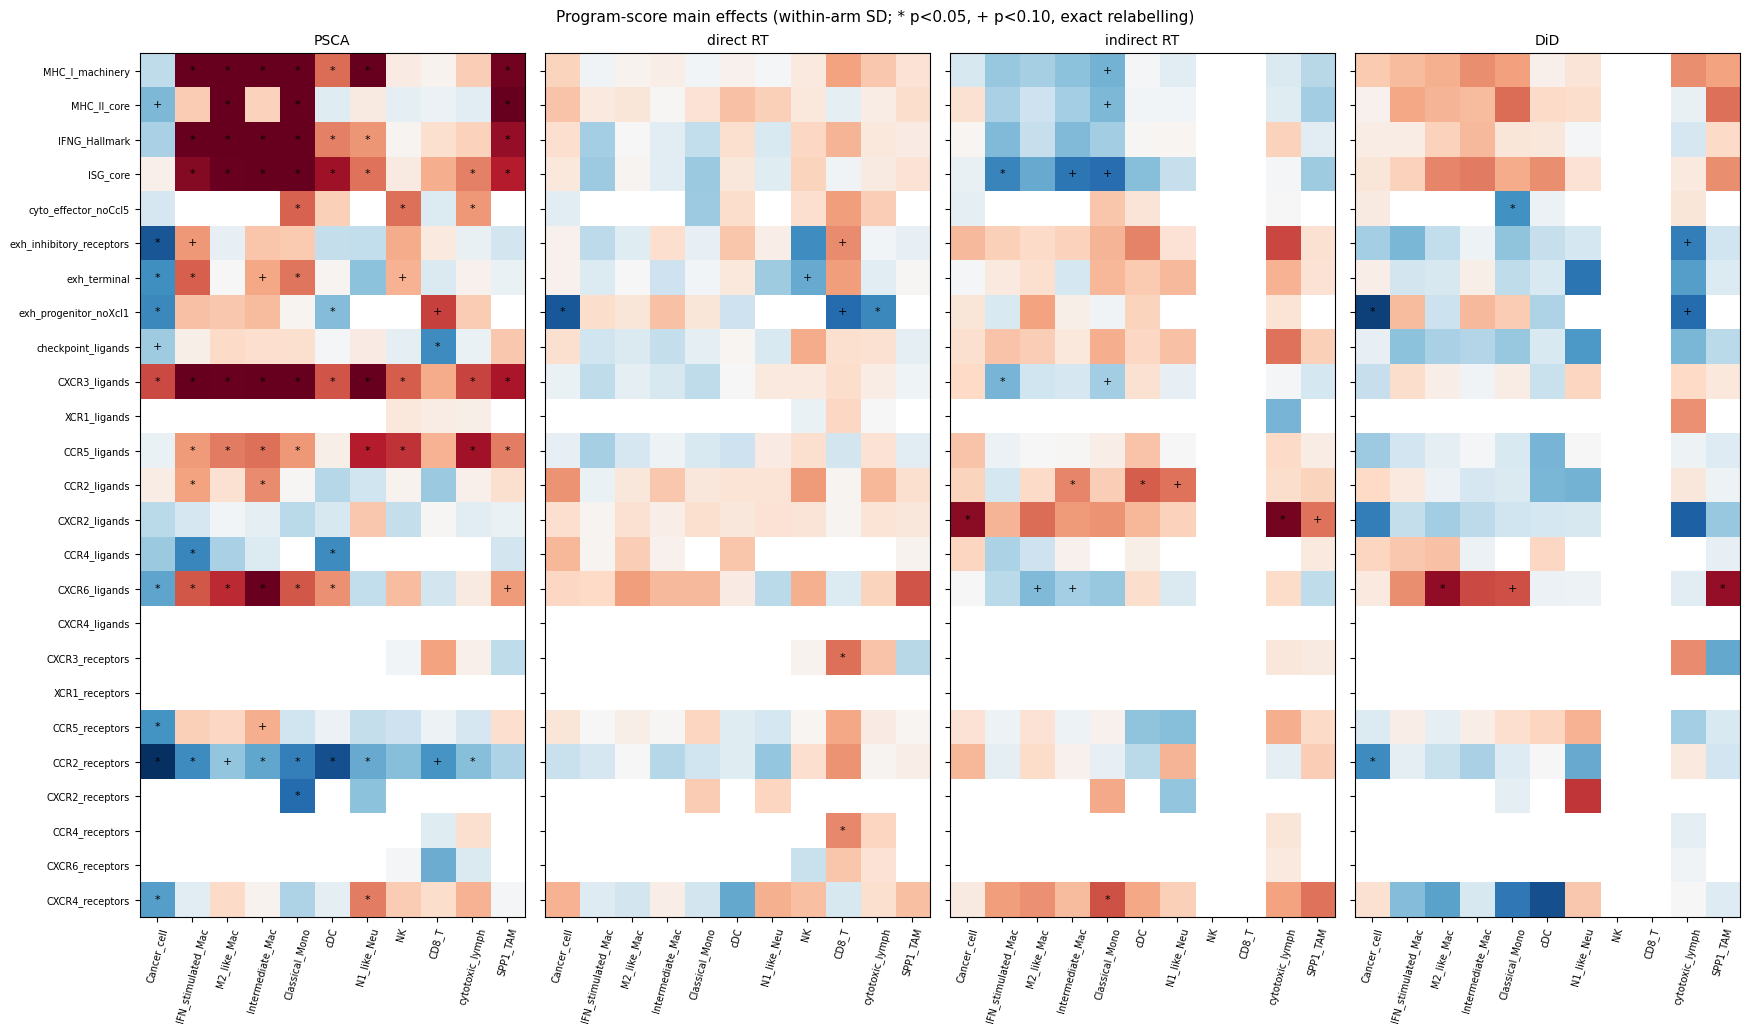

In [8]:
HEAD = ["MHC_I_machinery", "MHC_II_core", "IFNG_Hallmark", "ISG_core", "cyto_effector_noCcl5",
        "exh_inhibitory_receptors", "exh_terminal", "exh_progenitor_noXcl1", "checkpoint_ligands"] + \
       [f"{a}_ligands" for a in AXES] + [f"{a}_receptors" for a in AXES]
EFFS = ["PSCA", "direct RT", "indirect RT", "DiD"]
fig, axes = plt.subplots(1, len(EFFS), figsize=(4.4*len(EFFS), 0.32*len(HEAD) + 2.5), sharey=True)
for ax, eff in zip(axes, EFFS):
    d = PT[PT.effect == eff]
    F = d.pivot_table(index="program", columns="group", values="main").reindex(index=HEAD, columns=GROUPS)
    Pm = d.pivot_table(index="program", columns="group", values="p_main").reindex(index=HEAD, columns=GROUPS)
    ax.imshow(F.values, cmap="RdBu_r", norm=TwoSlopeNorm(0, -2, 2), aspect="auto")
    for i in range(F.shape[0]):
        for j in range(F.shape[1]):
            if pd.notna(Pm.values[i, j]) and Pm.values[i, j] < 0.10:
                ax.text(j, i, "*" if Pm.values[i, j] < 0.05 else "+", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(len(GROUPS))); ax.set_xticklabels(GROUPS, rotation=75, fontsize=7)
    ax.set_title(eff, fontsize=10)
axes[0].set_yticks(range(len(HEAD))); axes[0].set_yticklabels(HEAD, fontsize=7)
fig.suptitle("Program-score main effects (within-arm SD; * p<0.05, + p<0.10, exact relabelling)", fontsize=11)
fig.tight_layout(); fig.savefig(FIG/"03_program_effects.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Summary

In [9]:
print("=" * 100); print("SUMMARY — report these back"); print("=" * 100)
print(f"\n[GSEA] {GS.groupby(['group', 'contrast']).ngroups} rankings x {GS.pathway.nunique():,} sets")
print("  positive control, Hallmark IFN-gamma NES (PSCA_nonRT / PSCA_RT / TxNoTx):")
for g_ in ["IFN_stimulated_Mac", "SPP1_TAM", "M2_like_Mac", "Classical_Mono"]:
    x = pc[pc.group == g_].set_index("contrast").NES
    print(f"    {g_:<20s} {x.get('PSCA_nonRT', np.nan):+.2f} / {x.get('PSCA_RT', np.nan):+.2f} / "
          f"{x.get('TxNoTx', np.nan):+.2f}")
print("\n  NOTE: GO 'T-cell-mediated cytotoxicity' is 26/57 MHC genes (B2m, H2-K1, H2-D1, ...) and the\n"
      "  leukocyte-cytotoxicity / cell-killing sets carry 34 MHC and Fc-receptor genes. In macrophages,\n"
      "  monocytes and tumour cells these sets read MHC, not killing; 05 reclassifies them.")
for eff in ["PSCA", "direct RT", "indirect RT", "DiD"]:
    d = SO[(SO.effect == eff) & SO.stands_out]
    print(f"\n[{eff}] stands out ({len(d)} of {int((SO.effect == eff).sum())} program x group cells):")
    for fm, dd in d.groupby("family"):
        print(f"    {fm:<18s} " + ", ".join(f"{r.program}@{r.group}({r.score_main:+.1f})" for _, r in dd.iterrows()))
n_it = int(PT[PT.effect.isin(["PSCA", "direct RT", "indirect RT"])].p_inter.notna().sum())
print(f"\n[CAR x RT] program scores with p_inter<0.05: {len(inter)} of {n_it} tests "
      f"(~{0.05*n_it:.0f} expected by chance alone — read the list as candidates, not findings)")
for _, r in inter.sort_values("p_inter").head(15).iterrows():
    print(f"    {r.effect:<11s} {r.program:<26s} @ {r.group:<18s} {r.d_1:+.2f} vs {r.d_2:+.2f}  p_inter={r.p_inter:.3f}")
print(f"\n[sensitivity] removing Ccl5 / Xcl1 flips the sign in {int(SENS.flip.sum())}/{len(SENS)} and changes "
      f"p<0.10 status in {int(SENS.sig_changes.sum())}/{len(SENS)} group x effect cells")
print(f"\n[files] {OUT}: gsea_all.parquet, gsea_family_replication.csv, program_score_contrasts.csv, "
      f"stands_out.csv, sensitivity_ccl5_xcl1.csv")
print("=" * 100)

SUMMARY — report these back

[GSEA] 105 rankings x 5,844 sets
  positive control, Hallmark IFN-gamma NES (PSCA_nonRT / PSCA_RT / TxNoTx):
    IFN_stimulated_Mac   +3.03 / +2.91 / +3.23
    SPP1_TAM             +3.16 / +3.21 / +3.34
    M2_like_Mac          +3.34 / +3.23 / +3.41
    Classical_Mono       +3.31 / +3.13 / +3.25

  NOTE: GO 'T-cell-mediated cytotoxicity' is 26/57 MHC genes (B2m, H2-K1, H2-D1, ...) and the
  leukocyte-cytotoxicity / cell-killing sets carry 34 MHC and Fc-receptor genes. In macrophages,
  monocytes and tumour cells these sets read MHC, not killing; 05 reclassifies them.

[PSCA] stands out (76 of 634 program x group cells):
    IFN                ISG_core@IFN_stimulated_Mac(+1.8), IFNG_Hallmark@IFN_stimulated_Mac(+2.5), IFNA_Hallmark@IFN_stimulated_Mac(+1.1), ISG_core@M2_like_Mac(+2.0), IFNG_Hallmark@M2_like_Mac(+2.2), IFNA_Hallmark@M2_like_Mac(+1.4), ISG_core@Intermediate_Mac(+3.9), IFNG_Hallmark@Intermediate_Mac(+3.4), IFNA_Hallmark@Intermediate_Mac(+2.5), IS